In [1]:
# Instalación: pip install pygmm

import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 0. CARGAR DATASET
# =======================================
# df = pd.read_csv("../data_collection_peru_csv/data_merge/COLLECT_COMP_PERU.csv")
df = pd.read_csv("../data_ready/COLLECT_COMP_dataset_treated.csv")
df_with_factors = pd.read_csv('../Aprendisaje/df_with_factors.csv')

In [11]:
# PASO 1: PREPARACIÓN DE VARIABLES PARA ACL
# ==========================================

# Opción A: Usar puntuaciones factoriales del AFE
acl_variables_continuous = [col for col in df_with_factors.columns if 'Factor_' in col]

# Opción B: Usar variables categóricas originales
# Convertir a dummies si es necesario
acl_variables_categorical = [
    'SCHLTYPE',      # Tipo de escuela
    'ST004D01T',    # Género
    'IMMIG',        # Estatus migratorio
    'REPEAT',       # Repetición de grado
    # Añade más según tu dataset
]

# Crear dataset para ACL
# Para este ejemplo, usaremos las puntuaciones factoriales + algunas categóricas
df_acl = df_with_factors[acl_variables_continuous].copy()

# Añadir variables categóricas como dummies
for cat_var in acl_variables_categorical:
    if cat_var in df_with_factors.columns:
        dummies = pd.get_dummies(df_with_factors[cat_var], prefix=cat_var)
        df_acl = pd.concat([df_acl, dummies], axis=1)

# Eliminar missing values
df_acl = df_acl.dropna()
print(f"Variables para ACL: {df_acl.shape[1]}")
print(f"Observaciones: {df_acl.shape[0]}")

# Estandarizar variables continuas
scaler = StandardScaler()
df_acl_scaled = pd.DataFrame(
    scaler.fit_transform(df_acl),
    columns=df_acl.columns,
    index=df_acl.index
)

Variables para ACL: 15
Observaciones: 6968



Probando 2 clases...
  BIC: -522738.72
  AIC: -524594.82
  Silhouette: 0.422

Probando 3 clases...
  BIC: -473720.99
  AIC: -476508.57
  Silhouette: 0.286

Probando 4 clases...
  BIC: -658002.23
  AIC: -661721.29
  Silhouette: 0.291

Probando 5 clases...
  BIC: -673421.41
  AIC: -678071.94
  Silhouette: 0.347

Probando 6 clases...
  BIC: -694368.04
  AIC: -699950.04
  Silhouette: 0.339

Probando 7 clases...
  BIC: -771017.14
  AIC: -777530.62
  Silhouette: 0.362


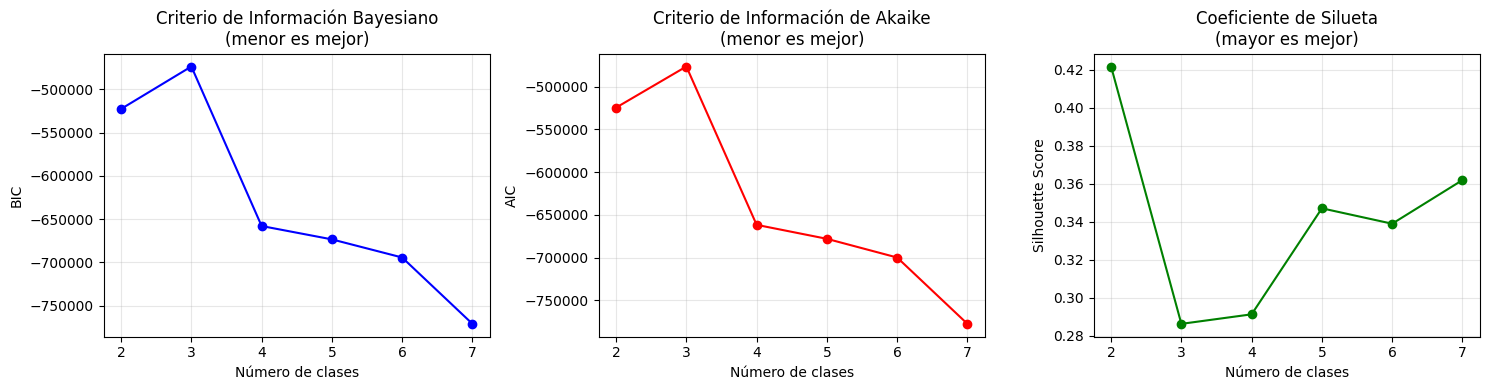

In [12]:
# PASO 2: DETERMINAR NÚMERO ÓPTIMO DE CLASES
# ===========================================

# Probar diferentes números de clases
n_classes_range = range(2, 8)
models = {}
bic_scores = []
aic_scores = []
silhouette_scores = []

from sklearn.metrics import silhouette_score

for n_classes in n_classes_range:
    print(f"\nProbando {n_classes} clases...")
    
    # Ajustar modelo
    gmm = GaussianMixture(
        n_components=n_classes,
        covariance_type='full',
        random_state=42,
        n_init=10,
        max_iter=200
    )
    gmm.fit(df_acl_scaled)
    
    # Guardar modelo
    models[n_classes] = gmm
    
    # Calcular criterios de información
    bic_scores.append(gmm.bic(df_acl_scaled))
    aic_scores.append(gmm.aic(df_acl_scaled))
    
    # Silhouette score
    labels = gmm.predict(df_acl_scaled)
    silhouette = silhouette_score(df_acl_scaled, labels)
    silhouette_scores.append(silhouette)
    
    print(f"  BIC: {bic_scores[-1]:.2f}")
    print(f"  AIC: {aic_scores[-1]:.2f}")
    print(f"  Silhouette: {silhouette:.3f}")

# Visualizar criterios
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# BIC
axes[0].plot(n_classes_range, bic_scores, 'bo-')
axes[0].set_xlabel('Número de clases')
axes[0].set_ylabel('BIC')
axes[0].set_title('Criterio de Información Bayesiano\n(menor es mejor)')
axes[0].grid(True, alpha=0.3)

# AIC
axes[1].plot(n_classes_range, aic_scores, 'ro-')
axes[1].set_xlabel('Número de clases')
axes[1].set_ylabel('AIC')
axes[1].set_title('Criterio de Información de Akaike\n(menor es mejor)')
axes[1].grid(True, alpha=0.3)

# Silhouette
axes[2].plot(n_classes_range, silhouette_scores, 'go-')
axes[2].set_xlabel('Número de clases')
axes[2].set_ylabel('Silhouette Score')
axes[2].set_title('Coeficiente de Silueta\n(mayor es mejor)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# PASO 3: SELECCIONAR NÚMERO ÓPTIMO DE CLASES
# ============================================

# Encontrar el óptimo basado en BIC (mínimo)
optimal_n_bic = n_classes_range[np.argmin(bic_scores)]
print(f"\nNúmero óptimo de clases según BIC: {optimal_n_bic}")

# Encontrar el óptimo basado en AIC
optimal_n_aic = n_classes_range[np.argmin(aic_scores)]
print(f"Número óptimo de clases según AIC: {optimal_n_aic}")

# Decisión final (puedes ajustar basado en interpretabilidad)
n_classes_final = optimal_n_bic  # o ajusta manualmente


Número óptimo de clases según BIC: 7
Número óptimo de clases según AIC: 7


In [14]:
# PASO 4: AJUSTAR MODELO FINAL
# =============================

gmm_final = models[n_classes_final]
class_labels = gmm_final.predict(df_acl_scaled)
class_probabilities = gmm_final.predict_proba(df_acl_scaled)

# Añadir clases al dataset
df_with_classes = df_with_factors.copy()
df_with_classes.loc[df_acl.index, 'latent_class'] = class_labels

# Calcular entropía (medida de certeza en la clasificación)
entropy = 1 + np.sum(class_probabilities * np.log(class_probabilities + 1e-10)) / (len(df_acl) * np.log(n_classes_final))
print(f"\nEntropía del modelo: {entropy:.3f}")
print("(Valores cercanos a 1 indican buena separación entre clases)")


Entropía del modelo: 1.000
(Valores cercanos a 1 indican buena separación entre clases)



PERFILES DE CLASES LATENTES

Distribución de clases:
  Clase 0: 1555 estudiantes (22.3%)
  Clase 1: 54 estudiantes (0.8%)
  Clase 2: 2014 estudiantes (28.9%)
  Clase 3: 2226 estudiantes (31.9%)
  Clase 4: 261 estudiantes (3.7%)
  Clase 5: 62 estudiantes (0.9%)
  Clase 6: 796 estudiantes (11.4%)

Factor_1_Score:
  Clase 0: μ=0.16 (σ=0.79)
  Clase 1: μ=-0.29 (σ=1.22)
  Clase 2: μ=0.05 (σ=0.97)
  Clase 3: μ=0.02 (σ=1.02)
  Clase 4: μ=-0.56 (σ=1.20)
  Clase 5: μ=0.21 (σ=0.85)
  Clase 6: μ=-0.31 (σ=1.17)

Factor_2_Score:
  Clase 0: μ=0.08 (σ=1.05)
  Clase 1: μ=0.05 (σ=1.09)
  Clase 2: μ=0.09 (σ=1.04)
  Clase 3: μ=-0.10 (σ=0.95)
  Clase 4: μ=-0.02 (σ=0.82)
  Clase 5: μ=-0.04 (σ=1.05)
  Clase 6: μ=-0.08 (σ=0.97)

Factor_3_Score:
  Clase 0: μ=0.27 (σ=1.05)
  Clase 1: μ=-0.04 (σ=1.07)
  Clase 2: μ=0.02 (σ=1.01)
  Clase 3: μ=-0.08 (σ=0.96)
  Clase 4: μ=-0.24 (σ=0.89)
  Clase 5: μ=0.05 (σ=0.92)
  Clase 6: μ=-0.26 (σ=0.90)

PV1MATH:
  Clase 0: μ=446.19 (σ=72.50)
  Clase 1: μ=353.59 (σ=77.49)
  Cl

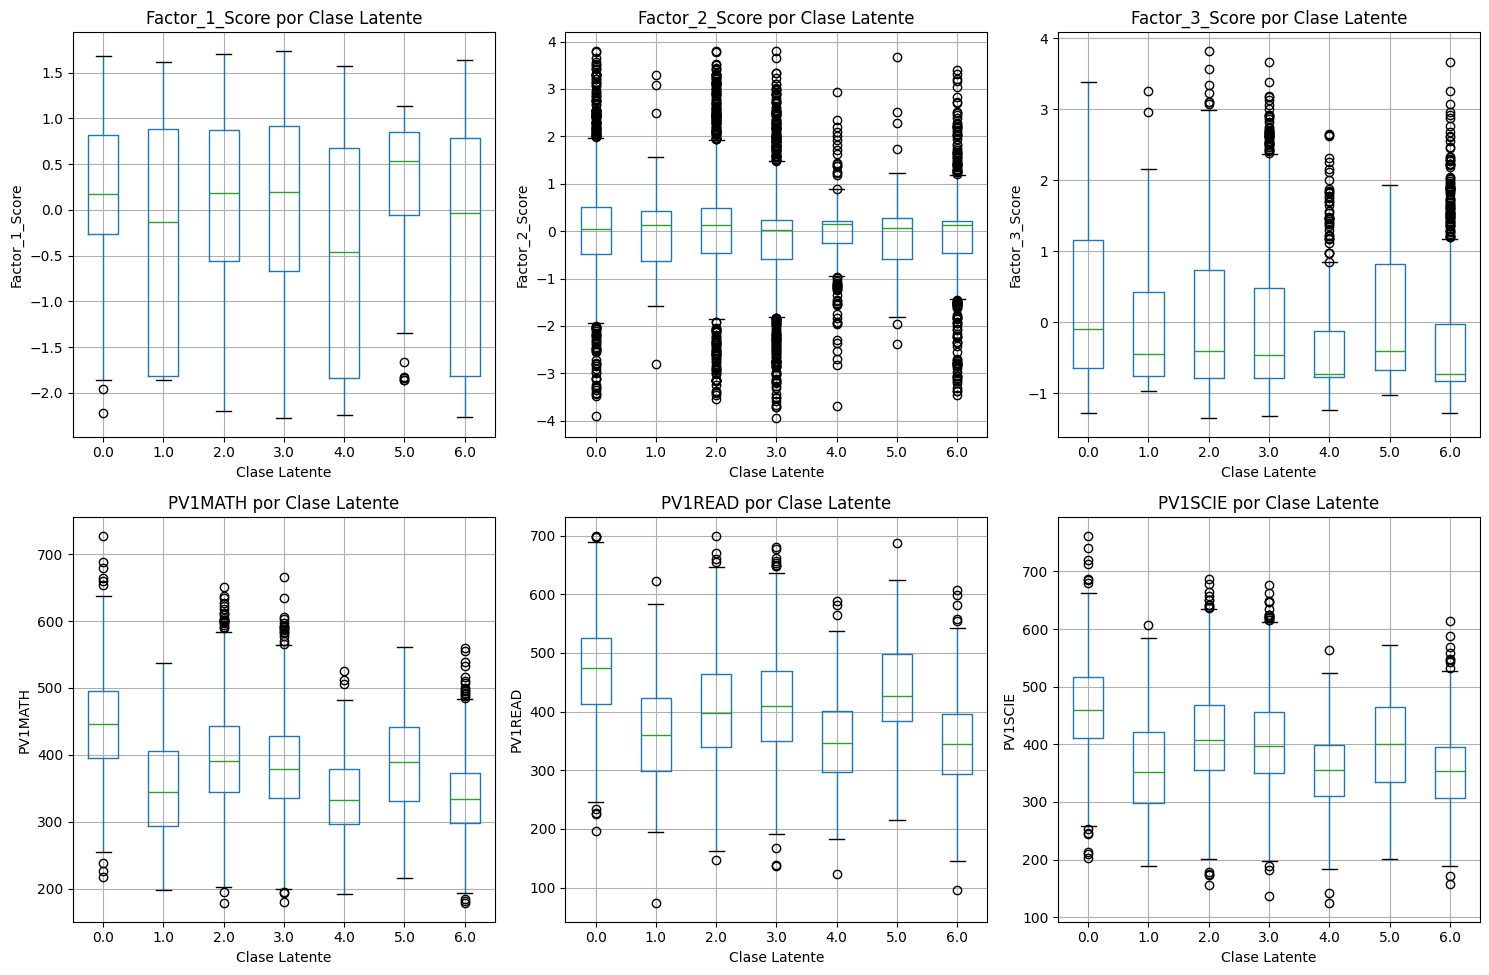

In [15]:
# PASO 5: PERFILAR LAS CLASES
# ============================

print(f"\n{'='*60}")
print("PERFILES DE CLASES LATENTES")
print(f"{'='*60}")

# Tamaño de cada clase
class_sizes = pd.Series(class_labels).value_counts().sort_index()
print("\nDistribución de clases:")
for i, size in class_sizes.items():
    pct = (size / len(class_labels)) * 100
    print(f"  Clase {i}: {size} estudiantes ({pct:.1f}%)")

# Caracterización por variables originales
profile_vars = acl_variables_continuous + ['PV1MATH', 'PV1READ', 'PV1SCIE']  # Añade rendimiento

for var in profile_vars:
    if var in df_with_classes.columns:
        print(f"\n{var}:")
        means = df_with_classes.groupby('latent_class')[var].mean()
        stds = df_with_classes.groupby('latent_class')[var].std()
        
        for clase in range(n_classes_final):
            print(f"  Clase {clase}: μ={means[clase]:.2f} (σ={stds[clase]:.2f})")

# Visualización de perfiles
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, var in enumerate(profile_vars[:6]):  # Primeras 6 variables
    if var in df_with_classes.columns:
        df_with_classes.boxplot(column=var, by='latent_class', ax=axes[idx])
        axes[idx].set_title(f'{var} por Clase Latente')
        axes[idx].set_xlabel('Clase Latente')
        axes[idx].set_ylabel(var)

plt.suptitle('')
plt.tight_layout()
plt.show()

In [16]:
# PASO 6: VALIDACIÓN DE LA SOLUCIÓN
# ==================================

# 6.1 Análisis discriminante para validar clases
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score

# Preparar datos
X_validation = df_acl_scaled
y_validation = class_labels

# LDA con validación cruzada
lda = LinearDiscriminantAnalysis()
scores = cross_val_score(lda, X_validation, y_validation, cv=5)
print(f"\nValidación de clases (LDA):")
print(f"Precisión promedio: {scores.mean():.3f} (+/- {scores.std():.3f})")
print("(Valores > 0.8 indican buena separación)")

# 6.2 ANOVA para diferencias entre clases
from scipy import stats

print("\nANOVA - Diferencias significativas entre clases:")
for var in profile_vars:
    if var in df_with_classes.columns:
        groups = [group[var].dropna() for name, group in df_with_classes.groupby('latent_class')]
        f_stat, p_value = stats.f_oneway(*groups)
        print(f"  {var}: F={f_stat:.2f}, p={p_value:.4e}", end="")
        if p_value < 0.001:
            print(" ***")
        elif p_value < 0.01:
            print(" **")
        elif p_value < 0.05:
            print(" *")
        else:
            print(" (n.s.)")


Validación de clases (LDA):
Precisión promedio: 0.278 (+/- 0.117)
(Valores > 0.8 indican buena separación)

ANOVA - Diferencias significativas entre clases:
  Factor_1_Score: F=35.33, p=2.4441e-42 ***
  Factor_2_Score: F=8.93, p=9.7094e-10 ***
  Factor_3_Score: F=33.64, p=3.0765e-40 ***
  PV1MATH: F=269.38, p=5.3363e-311 ***
  PV1READ: F=226.34, p=6.5387e-265 ***
  PV1SCIE: F=211.37, p=1.4732e-248 ***


In [17]:
# PASO 7: INTERPRETACIÓN Y ETIQUETADO
# ====================================

# Crear resumen interpretativo
print(f"\n{'='*60}")
print("INTERPRETACIÓN SUGERIDA DE CLASES")
print(f"{'='*60}")

# Analizar características distintivas de cada clase
for clase in range(n_classes_final):
    print(f"\nCLASE {clase}:")
    clase_data = df_with_classes[df_with_classes['latent_class'] == clase]
    
    # Rendimiento promedio
    if 'PV1MATH' in clase_data.columns:
        math_mean = clase_data['PV1MATH'].mean()
        print(f"  Rendimiento matemático: {math_mean:.1f}")
    
    # Factores promedio
    for col in acl_variables_continuous:
        if col in clase_data.columns:
            factor_mean = clase_data[col].mean()
            # Interpretar como alto/medio/bajo
            if factor_mean > 0.5:
                nivel = "Alto"
            elif factor_mean < -0.5:
                nivel = "Bajo"
            else:
                nivel = "Medio"
            print(f"  {col}: {nivel} ({factor_mean:.2f})")
    
    # Sugerencia de etiqueta
    print(f"  Etiqueta sugerida: [Analizar basado en patrones]")

# Guardar resultados
df_with_classes['latent_class_prob_max'] = class_probabilities.max(axis=1)
print(f"\nResultados guardados. Dataset actualizado con {n_classes_final} clases latentes.")


INTERPRETACIÓN SUGERIDA DE CLASES

CLASE 0:
  Rendimiento matemático: 446.2
  Factor_1_Score: Medio (0.16)
  Factor_2_Score: Medio (0.08)
  Factor_3_Score: Medio (0.27)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 1:
  Rendimiento matemático: 353.6
  Factor_1_Score: Medio (-0.29)
  Factor_2_Score: Medio (0.05)
  Factor_3_Score: Medio (-0.04)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 2:
  Rendimiento matemático: 395.7
  Factor_1_Score: Medio (0.05)
  Factor_2_Score: Medio (0.09)
  Factor_3_Score: Medio (0.02)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 3:
  Rendimiento matemático: 383.6
  Factor_1_Score: Medio (0.02)
  Factor_2_Score: Medio (-0.10)
  Factor_3_Score: Medio (-0.08)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 4:
  Rendimiento matemático: 337.3
  Factor_1_Score: Bajo (-0.56)
  Factor_2_Score: Medio (-0.02)
  Factor_3_Score: Medio (-0.24)
  Etiqueta sugerida: [Analizar basado en patrones]

CLASE 5:
  Rendimiento matem

In [18]:
df_with_classes

,CNTSCHID,CNTSTUID,STRATUM,BOOKID,RDESIGN,RCORE_TEST,RCORE_PERF,RS1_LEV,RS1_TEST,RCO1S_PERF,...,PV7SCIC,PV8SCIC,PV9SCIC,PV10SCIC,VER_DAT,Factor_1_Score,Factor_2_Score,Factor_3_Score,latent_class,latent_class_prob_max
0,60400034.0,60400002.0,PER01,Form 5,Design A (Stage1 then Stage2),Testlet 1,Low Level,Low,Testlet 14,Low Level,...,346.531,398.469,405.563,364.602,02MAY23:13:48:32,-0.554859,-2.230431,0.362899,6.0,1.0
1,60400267.0,60400006.0,PER02,Form 15,Not used,Not used,Not used,Not used,Not used,Not used,...,384.288,385.746,338.499,358.010,02MAY23:13:48:33,1.099952,0.166243,-0.897142,2.0,1.0
2,60400224.0,60400008.0,PER01,Form 43,Not used,Not used,Not used,Not used,Not used,Not used,...,311.251,384.335,304.553,315.926,02MAY23:13:48:32,-0.439671,0.094542,-0.661092,2.0,1.0
3,60400187.0,60400010.0,PER02,Form 4,Design A (Stage1 then Stage2),Testlet 1,Medium Level,Low,Testlet 14,Low Level,...,359.725,339.249,315.577,372.093,02MAY23:13:48:33,0.703798,-0.753302,1.841385,4.0,1.0
4,60400102.0,60400011.0,PER03,Form 24,Not used,Not used,Not used,Not used,Not used,Not used,...,422.710,411.513,431.318,400.626,02MAY23:13:48:33,-1.837957,0.178289,-0.737534,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6963,60400176.0,60409527.0,PER01,Form 44,Not used,Not used,Not used,Not used,Not used,Not used,...,383.592,327.241,393.202,463.055,02MAY23:13:48:32,0.443079,-0.676843,-0.510189,3.0,1.0
6964,60400010.0,60409529.0,PER02,Form 9,Design A (Stage1 then Stage2),Testlet 3,Medium Level,High,Testlet 13,Low Level,...,363.265,436.983,434.046,362.291,02MAY23:13:48:33,1.084172,0.349122,-0.892553,3.0,1.0
6965,60400277.0,60409531.0,PER03,Form 8,Design B (Stage2 then Stage1),Testlet 5,Medium Level,High,Testlet 12,Medium Level,...,434.954,487.241,410.435,493.333,02MAY23:13:48:34,1.143666,-0.119576,-0.811254,0.0,1.0
6966,60400177.0,60409533.0,PER02,Form 22,Not used,Not used,Not used,Not used,Not used,Not used,...,427.045,443.615,421.701,420.300,02MAY23:13:48:33,0.186809,-0.657467,-0.476496,2.0,1.0


In [20]:
# PASO 6.5: CREACION DE NUEVO DATASET CON VARIABLES UPDATEADAS Y REDUCIDAS
# ===========================================

# GENERAR ARCHIVO PARA ANALISIS DE CLASES LATENTES
df_with_classes.to_csv("df_with_classes.csv", index=False)
df_acl_scaled.to_csv("df_acl_scaled.csv", index=False)